# MUM – zadanie 1

In [1]:
library(tidyverse)
library(sqldf)
library(gridExtra)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Ładowanie wymaganego pakietu: gsubfn



Ładowanie wymaganego pakietu: proto



Ładowanie wymaganego pakietu: RSQLite




Dołączanie pakietu: 'gridExtra'




Następujący obiekt został zakryty z 'package:dplyr':

    combine




Typy kolumn ustawiłem w `col_types`. EA wczytałem jako tekst, bo to kod regionu, a INDUPDT jako datę.
Daty są zapisane jako miesiąc/dzień/rok (pierwsza liczba nigdy nie przekracza 12), dlatego podałem format w `locale`.

In [2]:
wesbrooks <- read_csv('http://jolej.linuxpl.info/Wesbrook.csv',
                      col_types = "ifnDiffffffffcffffinnnnnnnfnnnn",
                      locale = locale(date_format = "%m/%d/%Y"))

Kolumny z wartościami Y/N zamieniłem na TRUE/FALSE. W `col_types` typ logiczny oznacza się literą `l`, ale nie mogłem
jej użyć, bo `read_csv()` traktuje jako wartości logiczne tylko TRUE/FALSE, T/F i 1/0. Wartości Y i N zamieniłby na NA,
dlatego wczytałem te kolumny jako factor i dopiero potem zamieniłem na TRUE/FALSE. WESBROOK zostawiłem jako factor,
bo to zmienna objaśniana.

In [3]:
wesbrooks <- wesbrooks %>%
  mutate(across(c(PARENT, CHILD, SPOUSE, FACSTAFF, ATHLTCS, OTHERACT), ~ .x == "Y"))

glimpse(wesbrooks)

Rows: 2,770
Columns: 31
$ ID       <int> 88, 152, 157, 158, 159, 160, 169, 206, 209, 218, 231, 238, 27…
$ WESBROOK <fct> Y, Y, Y, Y, Y, Y, Y, Y, Y, Y, Y, Y, N, Y, Y, N, Y, N, N, N, Y…
$ TOTLGIVE <dbl> 24728, 23500, 3000, 7600, 20000, 7829, 2476, 5000, 13611, 685…
$ INDUPDT  <date> 1995-10-02, 1997-07-21, 1994-08-22, 1996-12-21, 1997-05-07, …
$ GRADYR1  <int> 1960, 1988, 1949, NA, 1958, NA, NA, 1993, 1937, 1990, 1958, N…
$ FACULTY1 <fct> CO, PO, AP, NA, LA, NA, NA, PO, AR, PO, CO, NA, AP, LA, LA, F…
$ DEPT1    <fct> CO, PO, AP, NA, LA, NA, NA, PO, AR, PO, CO, NA, AP, LA, LA, F…
$ MAJOR1   <fct> NA, NA, CIVL, NA, NA, NA, NA, NA, NA, NA, NA, NA, GEOE, NA, N…
$ PARENT   <lgl> TRUE, FALSE, TRUE, FALSE, TRUE, TRUE, FALSE, TRUE, TRUE, TRUE…
$ CHILD    <lgl> TRUE, FALSE, FALSE, FALSE, TRUE, FALSE, FALSE, TRUE, TRUE, FA…
$ SPOUSE   <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, FALSE, TRUE, TRUE, TRUE, TRUE, …
$ SEX      <fct> M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, F, F, M…
$ MARITAL  <fct>

# Wstępna analiza zmiennych
Na początek pogrupowałem kolumny tematycznie, żeby łatwiej było je analizować:
* dane techniczne - ID (numer rekordu), INDUPDT (data aktualizacji rekordu), EA (kod regionu)
* wpłaty - TOTLGIVE (łączna kwota darowizn), WESBROOK (czy osoba należy do grupy Wesbrook – zmienna objaśniana)
* studia na UBC - GRADYR1 (rok uzyskania stopnia), FRSTYEAR (rok pierwszego stopnia), FACULTY1 (wydział), DEPT1 (katedra), MAJOR1 (kierunek)
* osoba - SEX, MARITAL (stan cywilny), PARENT (rodzic studenta UBC), CHILD (dziecko absolwenta), SPOUSE (małżonek studenta lub absolwenta),
  FACSTAFF (pracownik UBC), ATHLTCS i OTHERACT (sport i inne aktywności), BIGBLOCK
* region zamieszkania - PROV (prowincja), HH_1PER … HH_45PER (odsetek gospodarstw 1, 2, 3 i 4-5 osobowych), AVE_INC i SD_INC (średni dochód i jego odchylenie),
  DWEL_VAL (średnia wartość mieszkania), MOV_DWEL (odsetek gospodarstw w domach mobilnych), CNDN_PCT (odsetek obywateli Kanady),
  ENG_PCT (odsetek osób z angielskim jako pierwszym językiem), OWN_PCT (odsetek właścicieli mieszkań)

Najpierw statystyki opisowe, podgląd pierwszych rekordów i liczba braków w każdej kolumnie.

In [4]:
summary(wesbrooks)

       ID         WESBROOK    TOTLGIVE         INDUPDT              GRADYR1    
 Min.   :    88   Y:1385   Min.   :     1   Min.   :1987-06-27   Min.   :1921  
 1st Qu.: 56836   N:1385   1st Qu.:   120   1st Qu.:1995-08-24   1st Qu.:1962  
 Median :107387            Median :  1000   Median :1996-10-31   Median :1976  
 Mean   :112929            Mean   :  3328   Mean   :1996-05-18   Mean   :1974  
 3rd Qu.:181532            3rd Qu.:  4234   3rd Qu.:1997-05-20   3rd Qu.:1988  
 Max.   :220512            Max.   :310150   Max.   :1999-09-16   Max.   :1999  
                                            NAs    :12           NAs    :947   
    FACULTY1       DEPT1         MAJOR1       PARENT          CHILD        
 GR     :357   AR     :400   CIVL   :  49   Mode :logical   Mode :logical  
 AR     :308   LA     :229   ENGL   :  40   FALSE:2486      FALSE:2691     
 LA     :225   CO     :223   ELEC   :  37   TRUE :284       TRUE :79       
 AP     :181   AP     :175   MECH   :  32               

In [5]:
sqldf('SELECT * FROM wesbrooks LIMIT 10')

ID,WESBROOK,TOTLGIVE,INDUPDT,GRADYR1,FACULTY1,DEPT1,MAJOR1,PARENT,CHILD,⋯,HH_2PER,HH_3PER,HH_45PER,AVE_INC,DWEL_VAL,PROV,CNDN_PCT,ENG_PCT,OWN_PCT,SD_INC
<int>,<fct>,<dbl>,<date>,<int>,<chr>,<chr>,<chr>,<lgl>,<lgl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
88,Y,24728,1995-10-02,1960,CO,CO,NA,TRUE,TRUE,⋯,0.2816901,0.11267606,0.32394366,147196,1153369,BC,0.7750000,0.6736402,0.7857143,529293.84
152,Y,23500,1997-07-21,1988,PO,PO,NA,FALSE,FALSE,⋯,0.2666667,0.20000000,0.23333333,151728,1667488,BC,0.8596491,0.8070175,0.8709677,215856.36
157,Y,3000,1994-08-22,1949,AP,AP,CIVL,TRUE,FALSE,⋯,0.3728814,0.10169492,0.06779661,162558,1153646,BC,0.9224806,0.8217054,0.2807018,919876.36
158,Y,7600,1996-12-21,NA,NA,NA,NA,FALSE,FALSE,⋯,0.3176471,0.07058824,0.04705882,45609,232647,BC,0.8000000,0.7777778,0.3647059,83574.13
159,Y,20000,1997-05-07,1958,LA,LA,NA,TRUE,TRUE,⋯,0.2816901,0.11267606,0.32394366,147196,1153369,BC,0.7750000,0.6736402,0.7857143,529293.84
160,Y,7829,1993-04-27,NA,NA,NA,NA,TRUE,FALSE,⋯,0.3250000,0.05000000,0.03750000,44348,667492,BC,0.8682171,0.8384615,0.1975309,64815.31
169,Y,2476,1994-12-08,NA,NA,NA,NA,FALSE,FALSE,⋯,0.3188406,0.14492754,0.39130435,152304,1148184,BC,0.8596491,0.8508772,0.8571429,317544.11
206,Y,5000,1997-07-21,1993,PO,PO,NA,TRUE,TRUE,⋯,0.6428571,0.21428571,0.00000000,NA,1090805,BC,0.9545455,0.9545455,0.7500000,NA
209,Y,13611,1992-07-17,1937,AR,AR,NA,TRUE,TRUE,⋯,0.1969697,0.18181818,0.50000000,181812,1074646,BC,0.8458498,0.7283465,0.9117647,408204.66


In [6]:
braki <- colSums(is.na(wesbrooks))
braki[braki > 0]

INDUPDT  GRADYR1 FACULTY1    DEPT1   MAJOR1  MARITAL       EA FRSTYEAR 
      12      947      947      947     1964     1815       13      947 
MOV_DWEL  HH_1PER  HH_2PER  HH_3PER HH_45PER  AVE_INC DWEL_VAL     PROV 
      28       28       28       28       28       71       28       17 
CNDN_PCT  ENG_PCT  OWN_PCT   SD_INC 
      29       28       28       71

W zbiorze jest sporo wartości NA, więc pytanie, czy wynikają z błędu, czy z braku danej cechy. Tu przydało się
pogrupowanie kolumn z początku tej części, bo braki układają się właśnie według tych grup:
* studia na UBC - GRADYR1, FACULTY1, DEPT1 i FRSTYEAR mają po 947 braków w tych samych wierszach. Są to osoby, które
  nie studiowały na UBC, czyli brak cechy, a nie błąd. MAJOR1 ma aż 1964 braki.
* region zamieszkania - w tych samych 28 wierszach brakuje wszystkich liczbowych danych o regionie (HH_*, DWEL_VAL,
  OWN_PCT itd.; AVE_INC i SD_INC mają dodatkowo po 43 braki). Tym osobom po prostu nie przypisano regionu.
* osoba - MARITAL ma 1815 braków, stan cywilny jest nieznany.
* dane techniczne - nie opisują samej osoby, dlatego odrzucam je w następnym kroku.

WESBROOK jest podzielona po równo (1385 Y i 1385 N). TOTLGIVE ma medianę 1000, ale maksimum 310 150, więc są tu duże wartości odstające.

Na początku odrzuciłem zmienne techniczne: ID (numer rekordu), EA (kod regionu, 1458 różnych wartości) i INDUPDT
(data aktualizacji rekordu w bazie). Nie mówią nic o samej osobie.

In [7]:
Wesbrook2 <- wesbrooks %>%
  select(-ID, -EA, -INDUPDT)

W `summary()` BIGBLOCK ma tylko wartość N, a MOV_DWEL ma medianę i 3. kwartyl równe 0 przy maksimum 0,81.
Sprawdziłem to dokładniej.

In [8]:
sqldf('SELECT BIGBLOCK, COUNT(*) AS liczba FROM wesbrooks GROUP BY BIGBLOCK')

sqldf('SELECT MOV_DWEL FROM wesbrooks WHERE MOV_DWEL > 0 ORDER BY MOV_DWEL DESC')

prop.table(table(wesbrooks$MOV_DWEL == 0))

BIGBLOCK,liczba
<fct>,<int>
N,2770


MOV_DWEL
<dbl>
0.8088235
0.6666667
0.4800000
0.4545455
0.4142857
0.4117647
0.3384615
0.3333333
0.3291139



     FALSE       TRUE 
0.02771699 0.97228301 

BIGBLOCK to stała, a MOV_DWEL jest różna od zera tylko w 76 rekordach (2,8%). Obie usuwam.

In [9]:
Wesbrook2 <- Wesbrook2 %>%
  select(-BIGBLOCK, -MOV_DWEL)

Histogram roczników ukończenia studiów i podział roczników na osoby z Wesbrook i pozostałe.

Warning message:
"Removed 947 rows containing non-finite outside the scale range (`stat_bin()`)."


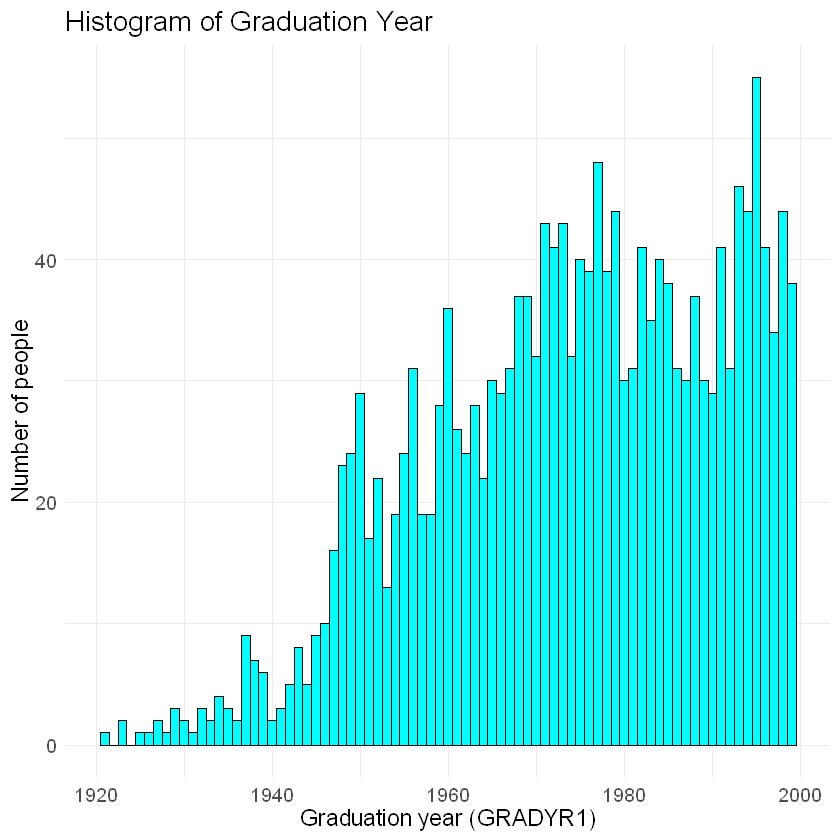

In [10]:
#histogram rocznikow ukonczenia studiow
wesbrooks %>%
  ggplot() +
  geom_histogram(
    mapping = aes(x = GRADYR1),
    binwidth = 1,
    fill = "cyan",
    color = "black"
  ) +
  labs(title = "Histogram of Graduation Year", x = "Graduation year (GRADYR1)", y = "Number of people") +
  theme_minimal() +
  theme(text = element_text(size = 14))

Warning message:
"Removed 947 rows containing non-finite outside the scale range
(`stat_count()`)."


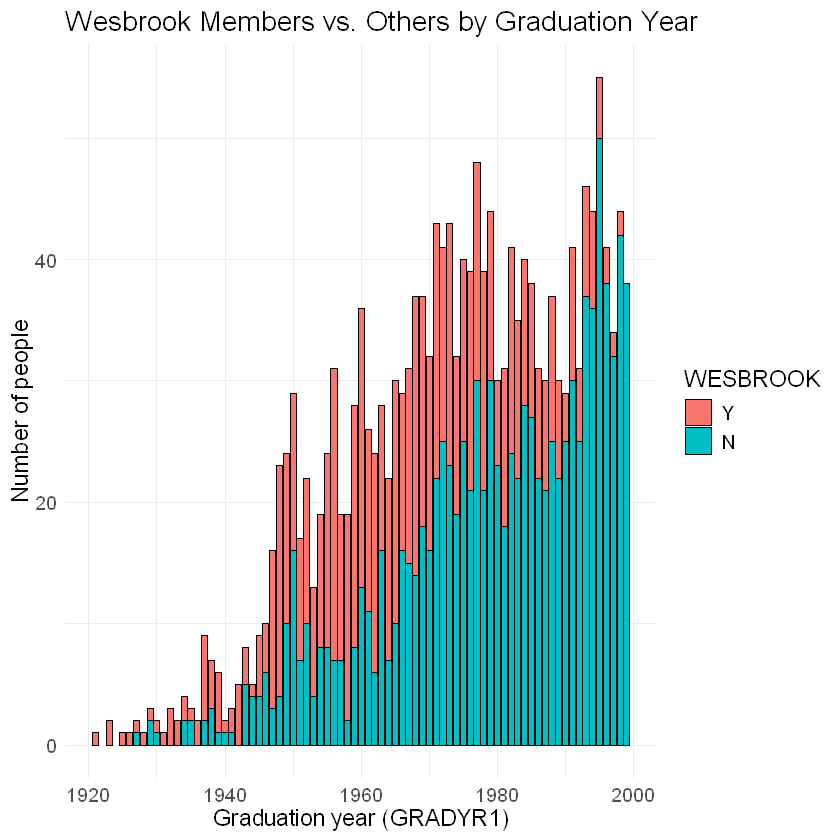

In [11]:
#histogram rocznikow ktore wplacaly oraz ktore nie
wesbrooks %>%
  ggplot() +
  geom_bar(mapping = aes(x = GRADYR1, fill = WESBROOK), color = "black") +
  labs(title = "Wesbrook Members vs. Others by Graduation Year", x = "Graduation year (GRADYR1)", y = "Number of people") +
  theme_minimal() +
  theme(text = element_text(size = 14))

Przy domyślnych 30 przedziałach histogram pokazywał ponad 100 osób na rocznik, bo jeden słupek łączył 2–3 lata,
dlatego ustawiłem `binwidth = 1`. Na drugim wykresie widać, że starsze roczniki częściej należą do Wesbrook,
a w najmłodszych jest ich coraz mniej (w latach 90. już tylko ok. 12%).

In [12]:
#brak zer ale wielka skala max i drugiego wyniku
sqldf('SELECT TOTLGIVE FROM wesbrooks ORDER BY TOTLGIVE DESC LIMIT 100')

TOTLGIVE
<dbl>
310150
43800
24980
24844
24728
24486
24148
23865
23800


Największa wpłata to 310 150, a druga 43 800. Ta jedna wartość psuje skalę wykresów, więc na wykresach ją odfiltrowuję.
Ze zbioru jej nie usuwam, bo nie wygląda na błąd.

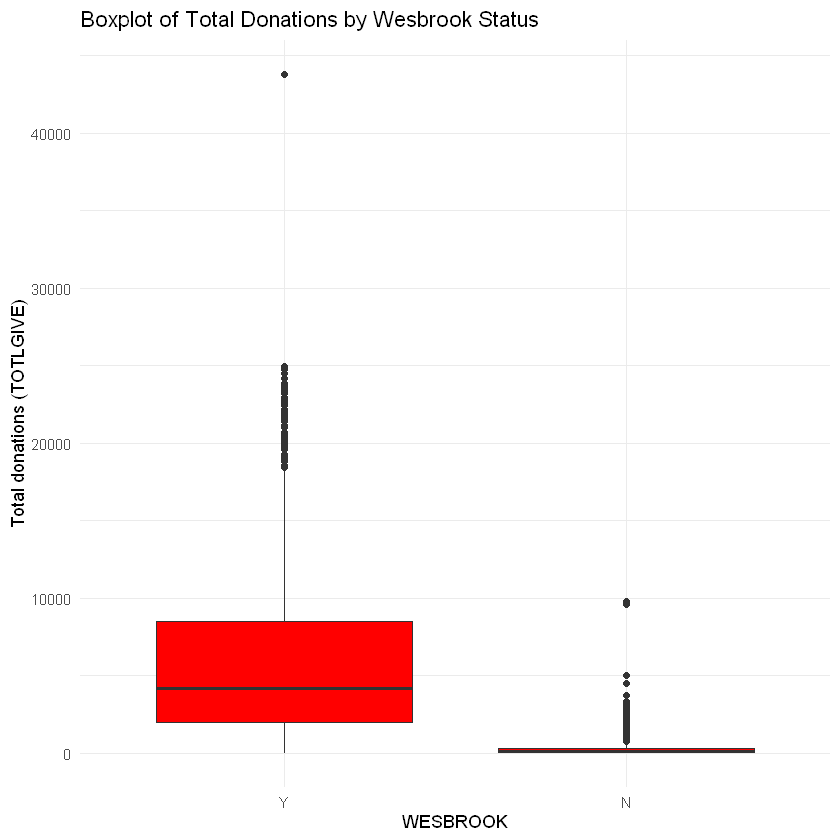

In [13]:
wesbrooks %>%
  filter(TOTLGIVE < 300000) %>%
  ggplot() +
  geom_boxplot(mapping = aes(x = WESBROOK, y = TOTLGIVE), fill = "red") +
  labs(title = "Boxplot of Total Donations by Wesbrook Status", x = "WESBROOK", y = "Total donations (TOTLGIVE)") +
  theme_minimal()

Warning message:
"Removed 947 rows containing missing values or values outside the scale range
(`geom_point()`)."


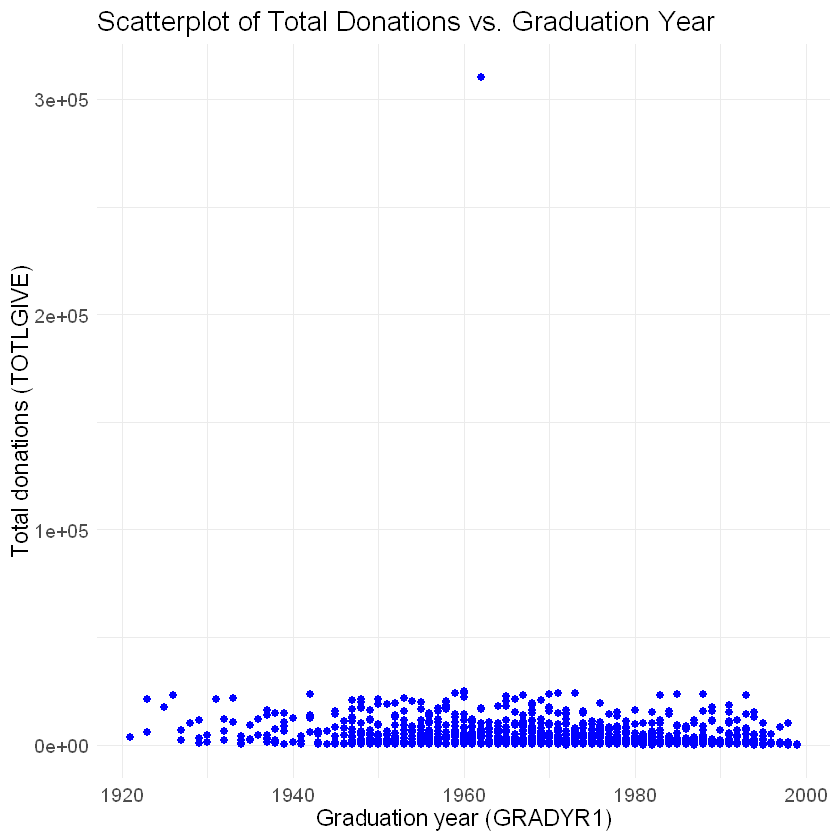

In [14]:
wesbrooks %>%
  ggplot() +
  geom_point(
    mapping = aes(x = GRADYR1, y = TOTLGIVE),
    color = "blue",
    size = 2
  ) +
  labs(title = "Scatterplot of Total Donations vs. Graduation Year",
       x = "Graduation year (GRADYR1)",
       y = "Total donations (TOTLGIVE)") +
  theme_minimal() +
  theme(text = element_text(size = 14))

Warning message:
"Removed 947 rows containing missing values or values outside the scale range
(`geom_point()`)."


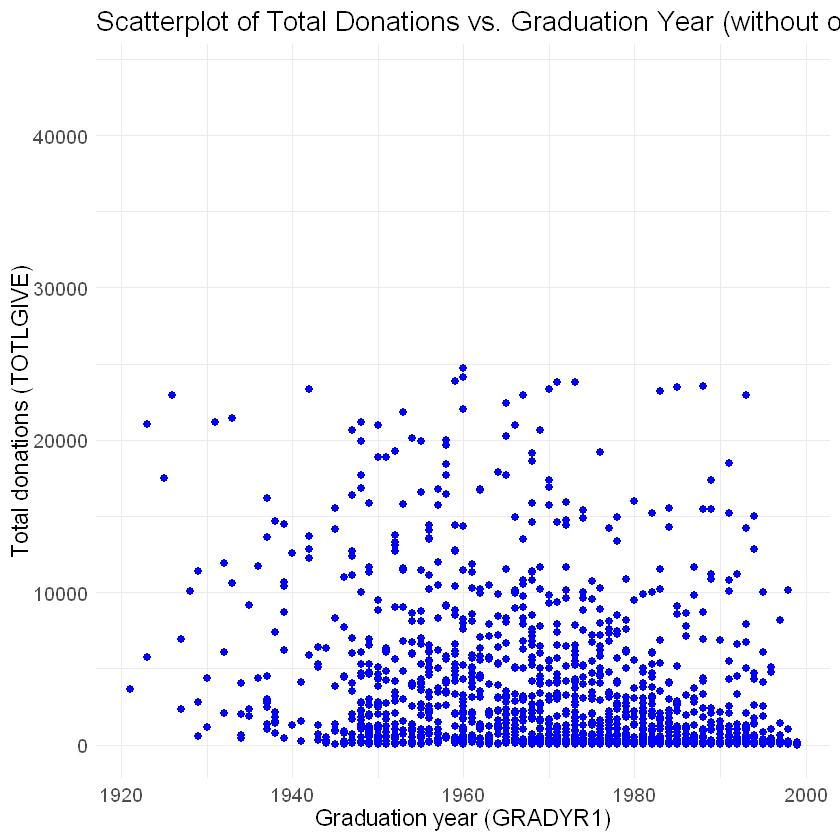

In [15]:
#wyrzucenie outliera z analizy (tylko na wykresie)
wesbrooks %>%
  filter(TOTLGIVE < 300000) %>%
  ggplot() +
  geom_point(
    mapping = aes(x = GRADYR1, y = TOTLGIVE),
    color = "blue",
    size = 2
  ) +
  labs(title = "Scatterplot of Total Donations vs. Graduation Year (without outlier)",
       x = "Graduation year (GRADYR1)",
       y = "Total donations (TOTLGIVE)") +
  theme_minimal() +
  theme(text = element_text(size = 14))

Mediana wpłat w grupie Y to 4201, a w N tylko 120. Na wykresie punktowym bez outliera widać, że starsze roczniki
wpłacają więcej, bo miały na to więcej czasu.

# Analiza istotności zmiennych
Zmienną uznaję za istotną, jeśli jej wartość coś mówi o tym, czy osoba należy do Wesbrook. W całym zbiorze Y i N jest
po 50%, więc gdyby zmienna nie miała znaczenia, w każdej jej kategorii też byłoby mniej więcej 50/50. Im bardziej odsetki
w kategoriach odbiegają od 50%, tym silniejsza jest zmienna.

Na początek pierwsze pytanie: czy TOTLGIVE jest na tyle silną cechą, że to od niej zależy WESBROOK? TOTLGIVE ma bardzo
dużo różnych wartości, więc podzieliłem ją na przedziały i sprawdziłem odsetek Y i N w każdym z nich.

In [16]:
wesbrooks %>%
  mutate(PRZEDZIAL = cut(TOTLGIVE, breaks = c(0, 100, 500, 1000, 5000, Inf), right = FALSE)) %>%
  select(PRZEDZIAL, WESBROOK) %>%
  table() %>%
  prop.table(margin = 1)

# prosta reguła: TOTLGIVE >= 1000 -> Y
table(wesbrooks$TOTLGIVE >= 1000, wesbrooks$WESBROOK)
mean((wesbrooks$TOTLGIVE >= 1000) == (wesbrooks$WESBROOK == "Y"))

               WESBROOK
PRZEDZIAL                 Y           N
  [0,100)       0.008532423 0.991467577
  [100,500)     0.012367491 0.987632509
  [500,1e+03)   0.031446541 0.968553459
  [1e+03,5e+03) 0.893848010 0.106151990
  [5e+03,Inf)   0.995238095 0.004761905

       
           Y    N
  FALSE   17 1294
  TRUE  1368   91

[1] 0.9610108

Poniżej 1000 do Wesbrook należy tylko 1–3% osób, a od 1000 wzwyż już 89–99%. Sama reguła „TOTLGIVE ≥ 1000 → Y”
trafnie przypisuje 96% osób (myli się w 108 przypadkach na 2770). Czyli tak, mając tylko TOTLGIVE da się bardzo dobrze
dopasować WESBROOK. TOTLGIVE jest więc praktycznie źródłem zmiennej objaśnianej, a nie zwykłą cechą. Dalej sprawdzam
pozostałe zmienne, które opisują samą osobę.

In [17]:
prop.table(table(wesbrooks$WESBROOK))

prop.table(table(wesbrooks$SEX,      wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$PARENT,   wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$CHILD,    wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$SPOUSE,   wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$FACSTAFF, wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$ATHLTCS,  wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$OTHERACT, wesbrooks$WESBROOK), margin = 1)


  Y   N 
0.5 0.5 

   
            Y         N
  M 0.5612789 0.4387211
  F 0.4042553 0.5957447

       
                Y         N
  FALSE 0.4766693 0.5233307
  TRUE  0.7042254 0.2957746

       
                Y         N
  FALSE 0.4934968 0.5065032
  TRUE  0.7215190 0.2784810

       
                Y         N
  FALSE 0.4408540 0.5591460
  TRUE  0.5988428 0.4011572

       
                Y         N
  FALSE 0.4587156 0.5412844
  TRUE  0.8935361 0.1064639

       
                Y         N
  FALSE 0.4920880 0.5079120
  TRUE  0.6145251 0.3854749

       
                Y         N
  FALSE 0.4812300 0.5187700
  TRUE  0.6766917 0.3233083

Y i N jest po 50%. SEX i wszystkie zmienne tak/nie różnicują WESBROOK. Np. wśród pracowników uczelni (FACSTAFF)
osób z Wesbrook jest 89%, a wśród pozostałych 46%. Wśród mężczyzn jest ich 56%, a wśród kobiet 40%. Zostawiam je wszystkie.

In [18]:
prop.table(table(wesbrooks$MARITAL,  wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$FACULTY1, wesbrooks$WESBROOK), margin = 1)
prop.table(table(wesbrooks$PROV,     wesbrooks$WESBROOK), margin = 1)

   
            Y         N
  M 0.6451204 0.3548796
  W 0.8611111 0.1388889
  S 0.1609195 0.8390805
  D 0.4000000 0.6000000
  G 1.0000000 0.0000000

    
              Y          N
  CO 0.40112994 0.59887006
  PO 0.94736842 0.05263158
  AP 0.22651934 0.77348066
  LA 0.75555556 0.24444444
  AR 0.42207792 0.57792208
  FR 0.28571429 0.71428571
  GR 0.40616246 0.59383754
  ME 0.54109589 0.45890411
  PH 0.03921569 0.96078431
  AG 0.24074074 0.75925926
  DE 0.51351351 0.48648649
  ED 0.27659574 0.72340426
  SC 0.14117647 0.85882353

    
             Y         N
  BC 0.5113029 0.4886971
  NT 0.0000000 1.0000000
  ON 0.4775281 0.5224719
  AB 0.3974359 0.6025641
  QC 0.2380952 0.7619048
  MB 0.3636364 0.6363636
  NS 0.2000000 0.8000000
  SK 0.3125000 0.6875000
  NF 0.2500000 0.7500000
  NB 0.0000000 1.0000000

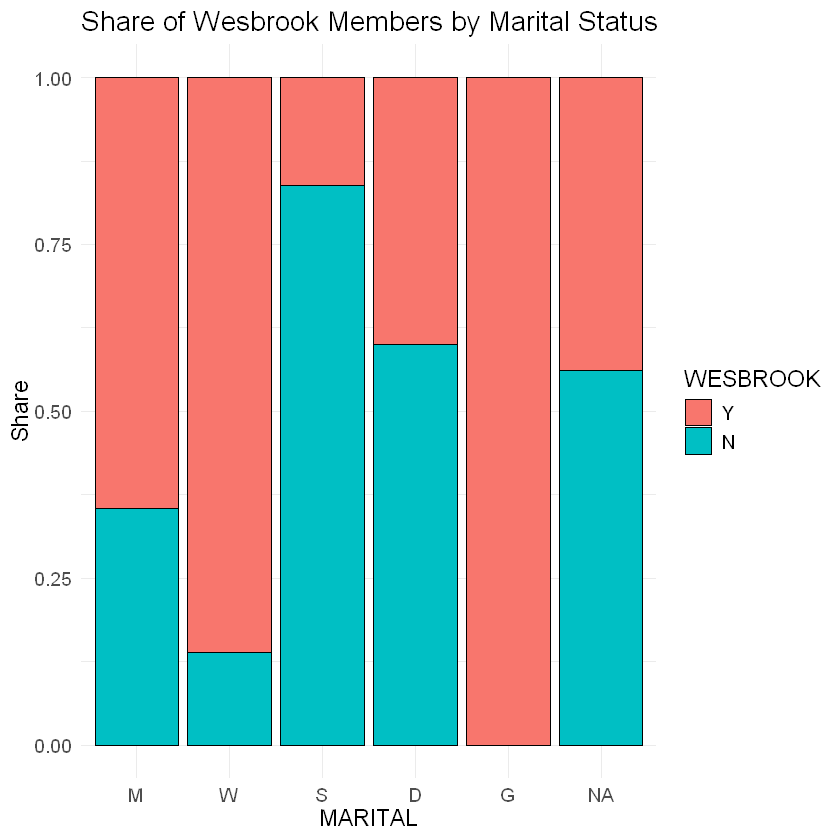

In [19]:
wesbrooks %>%
  ggplot() +
  geom_bar(mapping = aes(x = MARITAL, fill = WESBROOK), color = "black", position = "fill") +
  labs(title = "Share of Wesbrook Members by Marital Status", x = "MARITAL", y = "Share") +
  theme_minimal() +
  theme(text = element_text(size = 14))

MARITAL mocno różnicuje WESBROOK: w stanie wolnym do Wesbrook należy 16% osób, w małżeństwie 65%, a wśród wdowców 86%.
FACULTY1 też, od 4% do 95% zależnie od wydziału. W PROV różnice są mniejsze, ale są, więc zostawiam wszystkie trzy.

In [20]:
wesbrooks %>%
  select(FACULTY1, DEPT1, MAJOR1) %>%
  summarize(across(everything(), list(kategorie = ~ n_distinct(.x, na.rm = TRUE),
                                      braki = ~ sum(is.na(.x)),
                                      procent_brakow = ~ round(mean(is.na(.x)) * 100, 1))))

FACULTY1_kategorie,FACULTY1_braki,FACULTY1_procent_brakow,DEPT1_kategorie,DEPT1_braki,DEPT1_procent_brakow,MAJOR1_kategorie,MAJOR1_braki,MAJOR1_procent_brakow
<int>,<int>,<dbl>,<int>,<int>,<dbl>,<int>,<int>,<dbl>
13,947,34.2,22,947,34.2,141,1964,70.9


MAJOR1 ma 141 kategorii i 71% braków, więc ją usuwam. DEPT1 to w dużej mierze dokładniejszy podział FACULTY1 na katedry,
czyli prawie ta sama informacja, więc zostawiam prostszą FACULTY1.

In [21]:
Wesbrook2 <- Wesbrook2 %>%
  select(-MAJOR1, -DEPT1)

Zmienne numeryczne porównałem na wykresach pudełkowych w zależności od WESBROOK.

Warning message:
"Removed 947 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 71 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 71 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 29 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


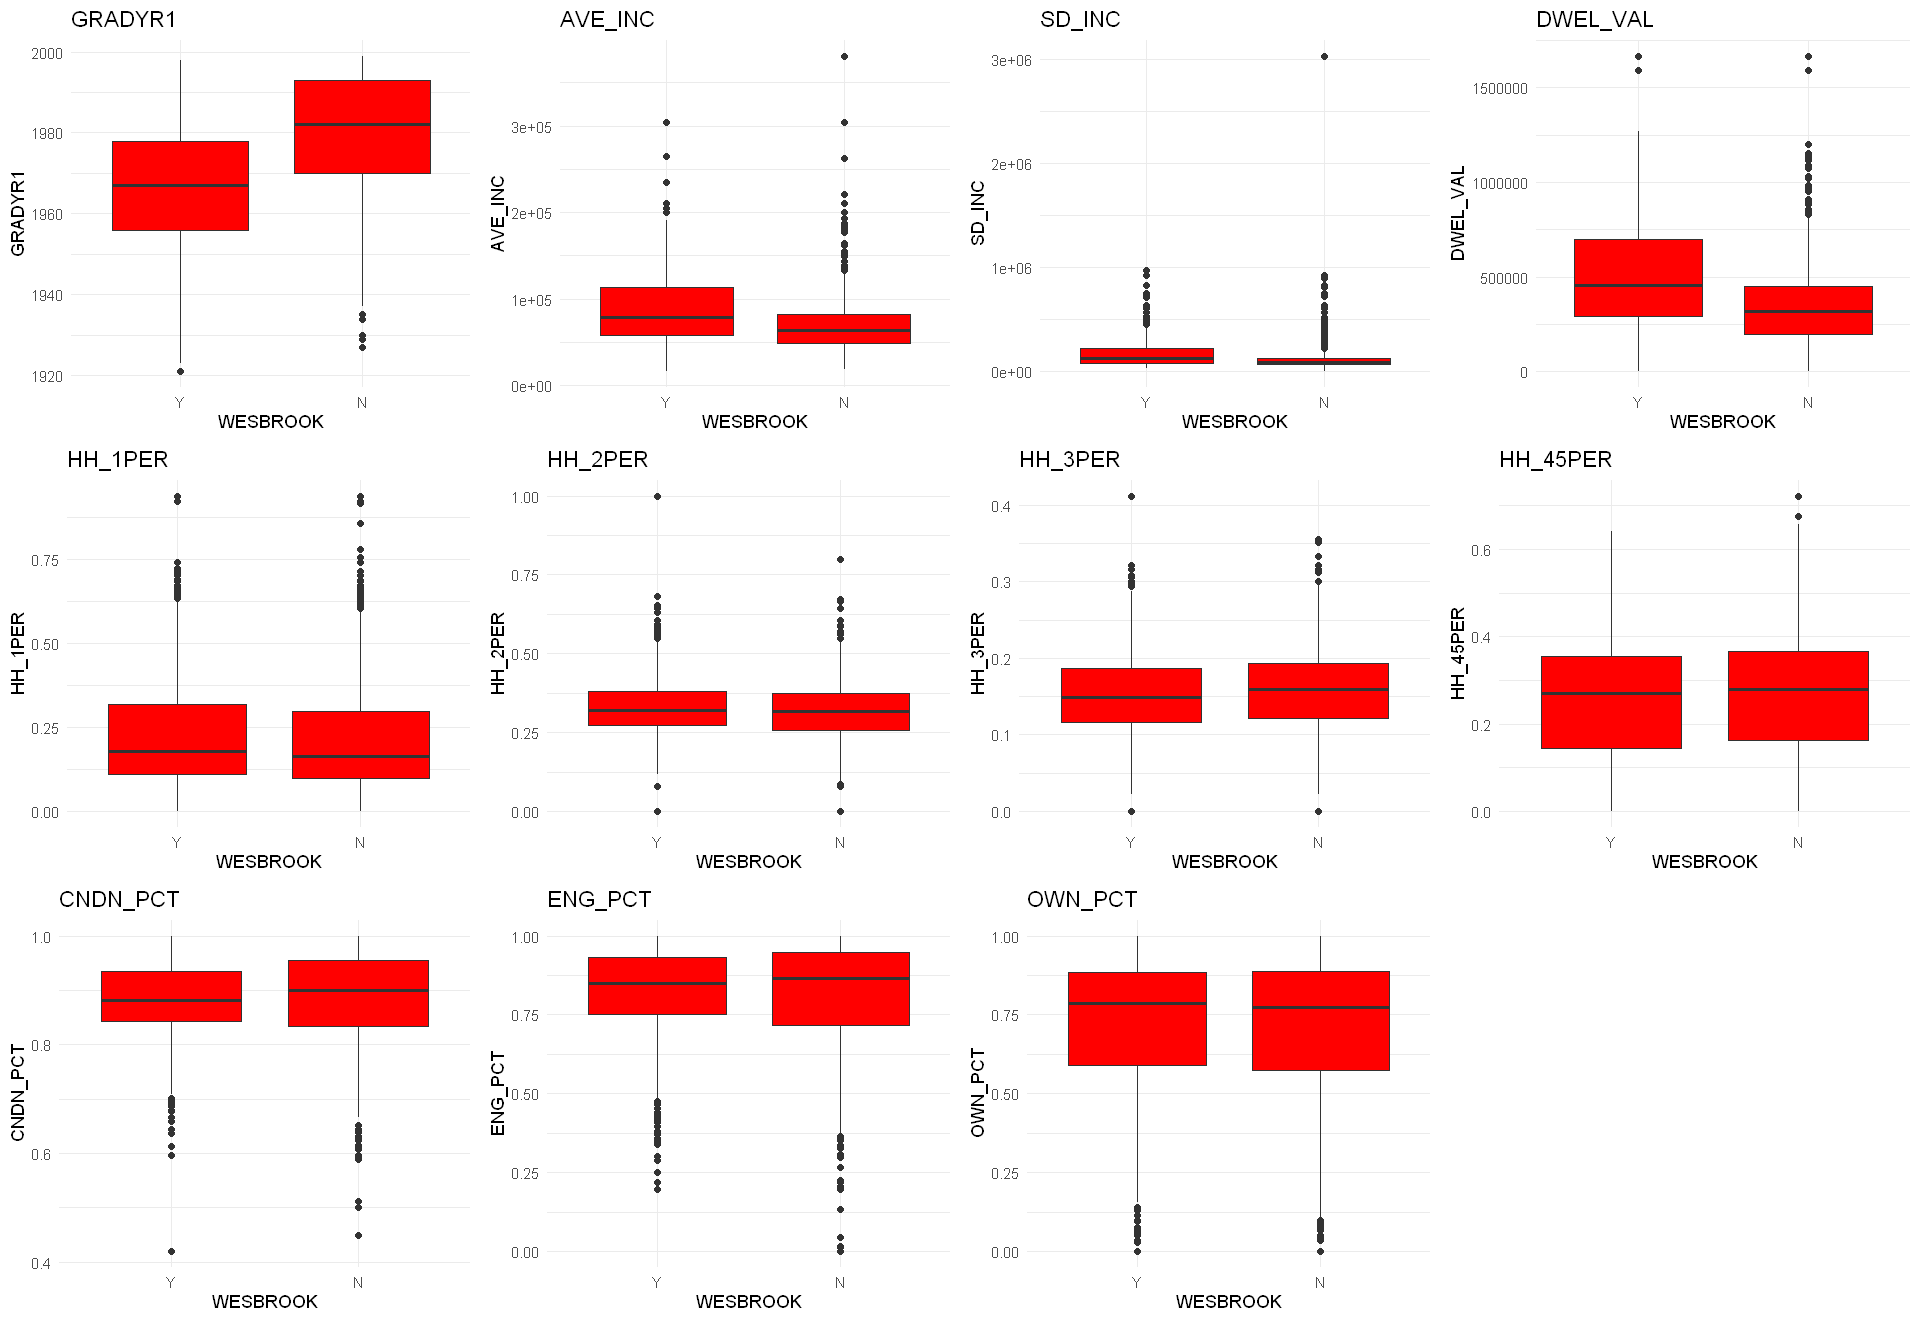

In [22]:
numeryczne <- c("GRADYR1", "AVE_INC", "SD_INC", "DWEL_VAL", "HH_1PER", "HH_2PER",
                "HH_3PER", "HH_45PER", "CNDN_PCT", "ENG_PCT", "OWN_PCT")

options(repr.plot.width = 16, repr.plot.height = 11)

pudelka <- lapply(numeryczne, function(kol) {
  wesbrooks %>%
    ggplot() +
    geom_boxplot(mapping = aes(x = WESBROOK, y = .data[[kol]]), fill = "red") +
    labs(title = kol, x = "WESBROOK", y = kol) +
    theme_minimal()
})
grid.arrange(grobs = pudelka, ncol = 4)

In [23]:
wesbrooks %>%
  group_by(WESBROOK) %>%
  summarize(across(all_of(numeryczne), ~ median(.x, na.rm = TRUE)))

WESBROOK,GRADYR1,AVE_INC,SD_INC,DWEL_VAL,HH_1PER,HH_2PER,HH_3PER,HH_45PER,CNDN_PCT,ENG_PCT,OWN_PCT
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Y,1967,79175,127825.59,454472,0.1773173,0.3191425,0.1483984,0.2702703,0.8818565,0.8508772,0.7866667
N,1982,63260,85314.85,317549,0.1623311,0.3157895,0.1594203,0.2792408,0.9000000,0.8642194,0.7727273


Wyraźną różnicę widać dla GRADYR1, AVE_INC, SD_INC i DWEL_VAL: osoby z Wesbrook skończyły studia wcześniej i mieszkają w bogatszych
regionach. Dla HH_*, CNDN_PCT, ENG_PCT i OWN_PCT pudełka są prawie takie same (mediany różnią się najwyżej o ok. 2 punkty procentowe),
więc różnice są bardzo małe i uznaję te zmienne za nieistotne.

In [24]:
Wesbrook2 <- Wesbrook2 %>%
  select(-HH_1PER, -HH_2PER, -HH_3PER, -HH_45PER, -CNDN_PCT, -ENG_PCT, -OWN_PCT)

Na koniec sprawdziłem korelacje pozostałych zmiennych numerycznych.

In [25]:
wesbrooks %>%
  select(TOTLGIVE, GRADYR1, FRSTYEAR, AVE_INC, SD_INC, DWEL_VAL) %>%
  cor(use = "pairwise.complete.obs") %>%
  round(2)

,TOTLGIVE,GRADYR1,FRSTYEAR,AVE_INC,SD_INC,DWEL_VAL
TOTLGIVE,1.00,-0.21,-0.22,0.08,0.05,0.13
GRADYR1,-0.21,1.00,0.96,-0.18,-0.14,-0.14
FRSTYEAR,-0.22,0.96,1.00,-0.18,-0.14,-0.15
AVE_INC,0.08,-0.18,-0.18,1.00,0.80,0.67
SD_INC,0.05,-0.14,-0.14,0.80,1.00,0.50
DWEL_VAL,0.13,-0.14,-0.15,0.67,0.50,1.00


GRADYR1 i FRSTYEAR są prawie identyczne (r = 0,96), a AVE_INC i SD_INC mocno skorelowane (r = 0,80). Z każdej pary
zostawiam jedną zmienną, więc usuwam FRSTYEAR i SD_INC. AVE_INC i DWEL_VAL mają r = 0,67, więc zostają obie.

In [26]:
Wesbrook2 <- Wesbrook2 %>%
  select(-FRSTYEAR, -SD_INC)

glimpse(Wesbrook2)

Rows: 2,770
Columns: 15
$ WESBROOK <fct> Y, Y, Y, Y, Y, Y, Y, Y, Y, Y, Y, Y, N, Y, Y, N, Y, N, N, N, Y…
$ TOTLGIVE <dbl> 24728, 23500, 3000, 7600, 20000, 7829, 2476, 5000, 13611, 685…
$ GRADYR1  <int> 1960, 1988, 1949, NA, 1958, NA, NA, 1993, 1937, 1990, 1958, N…
$ FACULTY1 <fct> CO, PO, AP, NA, LA, NA, NA, PO, AR, PO, CO, NA, AP, LA, LA, F…
$ PARENT   <lgl> TRUE, FALSE, TRUE, FALSE, TRUE, TRUE, FALSE, TRUE, TRUE, TRUE…
$ CHILD    <lgl> TRUE, FALSE, FALSE, FALSE, TRUE, FALSE, FALSE, TRUE, TRUE, FA…
$ SPOUSE   <lgl> TRUE, TRUE, TRUE, TRUE, TRUE, FALSE, TRUE, TRUE, TRUE, TRUE, …
$ SEX      <fct> M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, M, F, F, M…
$ MARITAL  <fct> M, M, M, M, M, W, M, M, M, M, M, M, NA, M, M, M, NA, M, M, NA…
$ FACSTAFF <lgl> FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE…
$ ATHLTCS  <lgl> TRUE, FALSE, TRUE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE, …
$ OTHERACT <lgl> FALSE, FALSE, TRUE, FALSE, FALSE, FALSE, FALSE, FALSE, FALSE,…
$ AVE_INC  <dbl>

W Wesbrook2 zostało 15 kolumn. TOTLGIVE zostawiłem, bo może się jeszcze przydać przy dalszej analizie. Przy predykcji
WESBROOK trzeba ją jednak usunąć, bo jak pokazała reguła TOTLGIVE ≥ 1000 (96% trafności), WESBROOK wynika prawie wprost z wpłat.

# Wizualna analiza zmiennych numerycznych
Histogramy zmiennych numerycznych z Wesbrook2 na jednym wykresie.

Warning message:
"Removed 947 rows containing non-finite outside the scale range (`stat_bin()`)."


Warning message:
"Removed 71 rows containing non-finite outside the scale range (`stat_bin()`)."


Warning message:
"Removed 28 rows containing non-finite outside the scale range (`stat_bin()`)."


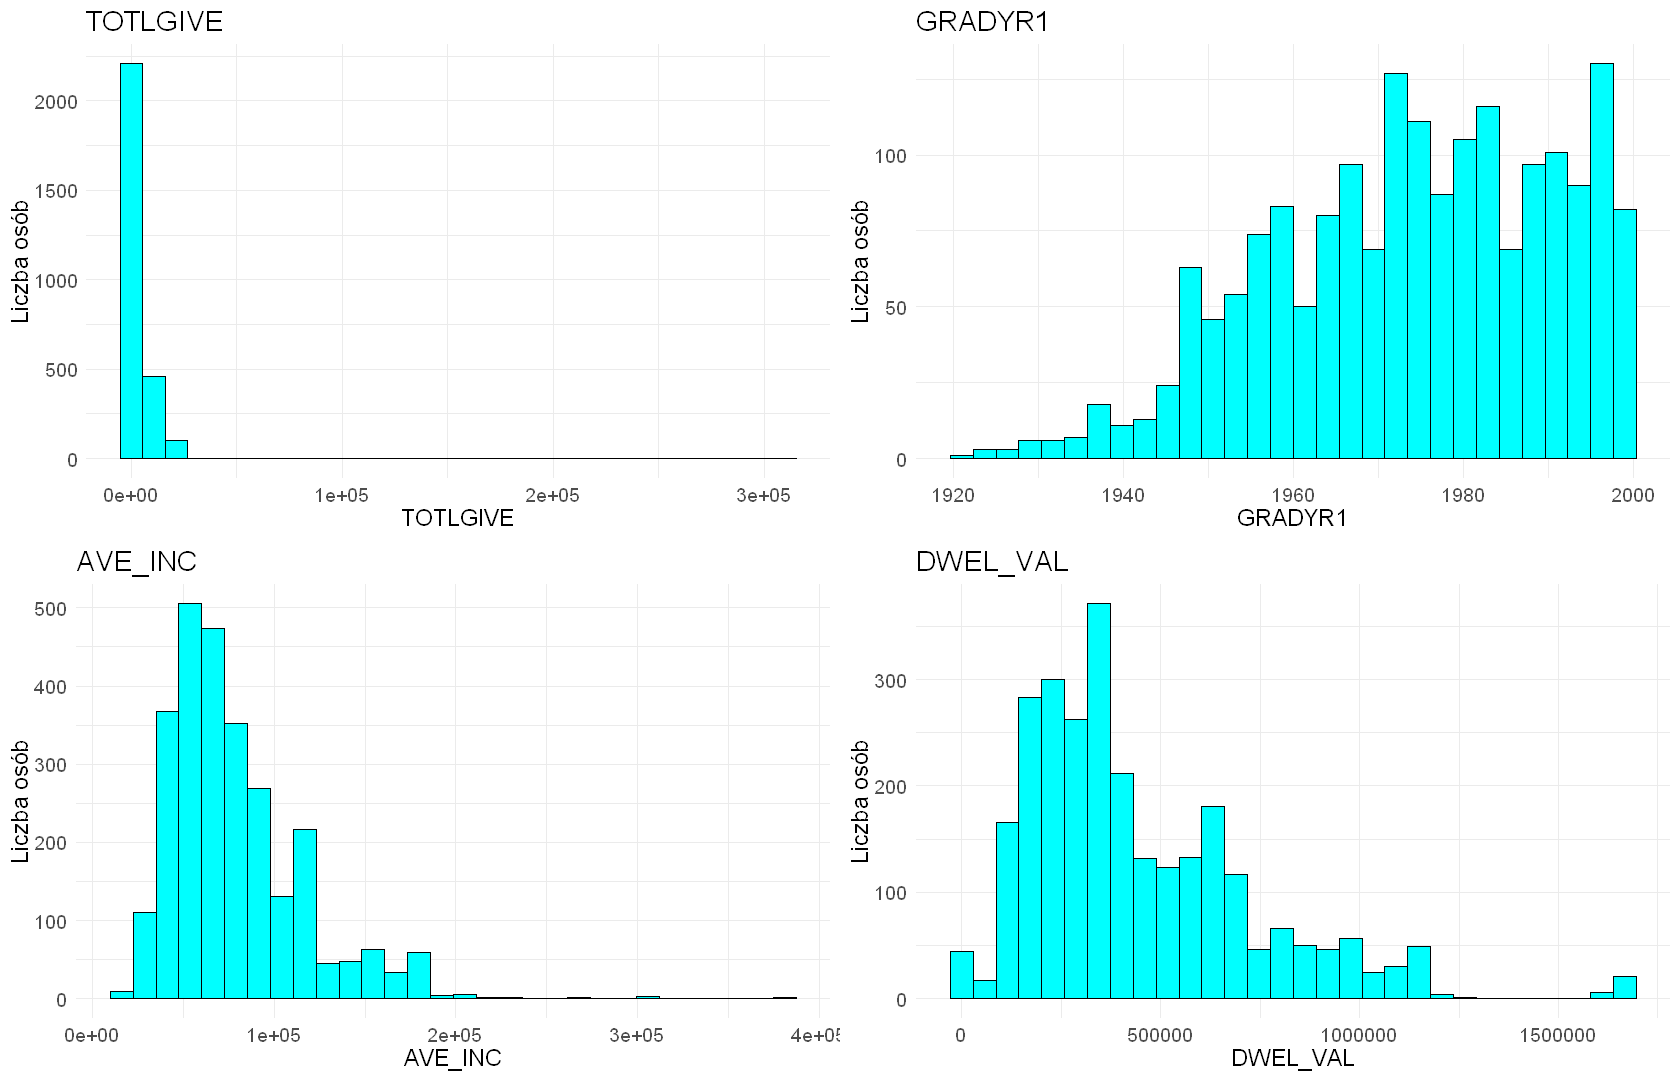

In [27]:
numeryczne2 <- c("TOTLGIVE", "GRADYR1", "AVE_INC", "DWEL_VAL")

options(repr.plot.width = 14, repr.plot.height = 9)

histogramy <- lapply(numeryczne2, function(kol) {
  Wesbrook2 %>%
    ggplot() +
    geom_histogram(mapping = aes(x = .data[[kol]]), bins = 30, fill = "cyan", color = "black") +
    labs(title = kol, x = kol, y = "Liczba osób") +
    theme_minimal() +
    theme(text = element_text(size = 14))
})
grid.arrange(grobs = histogramy, ncol = 2)

* TOTLGIVE - ok. 80% osób jest w pierwszym słupku, bo wartość 310 150 rozciąga oś; rozkład skrajnie prawostronnie skośny
* GRADYR1 - lewostronnie skośny, więcej osób z nowszych roczników
* AVE_INC - prawostronnie skośny, większość regionów ma przeciętne dochody, a tylko nieliczne bardzo wysokie
* DWEL_VAL - też prawostronnie skośny, ale łagodniej niż AVE_INC

# Imputacja brakujących danych

In [28]:
braki2 <- colSums(is.na(Wesbrook2))
braki2[braki2 > 0]

GRADYR1 FACULTY1  MARITAL  AVE_INC DWEL_VAL     PROV 
     947      947     1815       71       28       17

* GRADYR1 - brak oznacza, że osoba nie studiowała na UBC. Zapisuję to w nowej zmiennej GRADUATED, a potem wstawiam medianę
* FACULTY1 - nowa kategoria NONE (z tego samego powodu)
* MARITAL - nowa kategoria U (nieznany)
* PROV - najczęstsza wartość, czyli BC
* AVE_INC, DWEL_VAL - mediana, bo rozkłady są skośne

In [29]:
Wesbrook2 <- Wesbrook2 %>%
  mutate(GRADUATED = !is.na(GRADYR1)) %>%
  mutate(GRADYR1 = ifelse(is.na(GRADYR1), median(GRADYR1, na.rm = TRUE), GRADYR1)) %>%
  mutate(FACULTY1 = as.factor(ifelse(is.na(FACULTY1), "NONE", as.character(FACULTY1)))) %>%
  mutate(MARITAL = as.factor(ifelse(is.na(MARITAL), "U", as.character(MARITAL)))) %>%
  mutate(PROV = as.factor(ifelse(is.na(PROV), "BC", as.character(PROV)))) %>%
  mutate(AVE_INC = ifelse(is.na(AVE_INC), median(AVE_INC, na.rm = TRUE), AVE_INC)) %>%
  mutate(DWEL_VAL = ifelse(is.na(DWEL_VAL), median(DWEL_VAL, na.rm = TRUE), DWEL_VAL))

sum(is.na(Wesbrook2))
summary(Wesbrook2)

[1] 0

 WESBROOK    TOTLGIVE         GRADYR1        FACULTY1     PARENT       
 Y:1385   Min.   :     1   Min.   :1921   NONE   :947   Mode :logical  
 N:1385   1st Qu.:   120   1st Qu.:1970   GR     :357   FALSE:2486     
          Median :  1000   Median :1976   AR     :308   TRUE :284      
          Mean   :  3328   Mean   :1975   LA     :225                  
          3rd Qu.:  4234   3rd Qu.:1981   AP     :181                  
          Max.   :310150   Max.   :1999   CO     :177                  
                                          (Other):575                  
   CHILD           SPOUSE        SEX      MARITAL   FACSTAFF      
 Mode :logical   Mode :logical   M:1689   D:   5   Mode :logical  
 FALSE:2691      FALSE:1733      F:1081   G:   2   FALSE:2507     
 TRUE :79        TRUE :1037               M: 789   TRUE :263      
                                          S:  87                  
                                          U:1815                  
                      

# Normalizacja danych
Zmienne numeryczne (TOTLGIVE, GRADYR1, AVE_INC, DWEL_VAL) normalizuję metodą z-score i min-max, każdą metodą do osobnego zbioru.

In [30]:
Wesbrook_z <- Wesbrook2 %>%
  mutate(across(where(is.numeric), ~ (.x - mean(.x)) / sd(.x)))

Wesbrook_mm <- Wesbrook2 %>%
  mutate(across(where(is.numeric), ~ ((.x - min(.x)) / (max(.x) - min(.x))) * (1 - 0) + 0))

Wesbrook_z %>%
  select(where(is.numeric)) %>%
  summary()

Wesbrook_mm %>%
  select(where(is.numeric)) %>%
  summary()

    TOTLGIVE          GRADYR1            AVE_INC           DWEL_VAL      
 Min.   :-0.4357   Min.   :-4.01207   Min.   :-1.6930   Min.   :-1.5514  
 1st Qu.:-0.4201   1st Qu.:-0.35454   1st Qu.:-0.6963   1st Qu.:-0.7255  
 Median :-0.3049   Median : 0.09332   Median :-0.2435   Median :-0.2858  
 Mean   : 0.0000   Mean   : 0.00000   Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.1186   3rd Qu.: 0.46653   3rd Qu.: 0.3794   3rd Qu.: 0.5696  
 Max.   :40.1750   Max.   : 1.81012   Max.   : 8.2664   Max.   : 4.3000  

    TOTLGIVE            GRADYR1          AVE_INC          DWEL_VAL     
 Min.   :0.0000000   Min.   :0.0000   Min.   :0.0000   Min.   :0.0000  
 1st Qu.:0.0003837   1st Qu.:0.6282   1st Qu.:0.1001   1st Qu.:0.1411  
 Median :0.0032210   Median :0.7051   Median :0.1455   Median :0.2163  
 Mean   :0.0107283   Mean   :0.6891   Mean   :0.1700   Mean   :0.2651  
 3rd Qu.:0.0136475   3rd Qu.:0.7692   3rd Qu.:0.2081   3rd Qu.:0.3625  
 Max.   :1.0000000   Max.   :1.0000   Max.   :1.0000   Max.   :1.0000  

Po z-score średnia wynosi 0, a po min-max wartości są w przedziale [0, 1].

Dalej używam wersji z-score, bo min-max źle znosi wartości odstające - o skali decydują tylko min i max. Przez wpłatę
310 150 wszystkie inne wartości TOTLGIVE lądują w przedziale 0 - 0,14 (mediana 0,003), więc różnice między osobami prawie
znikają. W z-score wartość odstająca dostaje po prostu duży wynik, ale nie ściska reszty danych. Min-max lepiej sprawdza się
przy danych o ograniczonym zakresie bez wartości odstających (np. odsetki 0 - 1).

# Kodowanie zerojedynkowe zmiennej MARITAL

In [31]:
library(dummies)

Wesbrook3 <- data.frame(Wesbrook_z)
Wesbrook3 <- dummy.data.frame(data = Wesbrook3, names = "MARITAL", sep = "_")

head(Wesbrook3)
colSums(select(Wesbrook3, starts_with("MARITAL")))

dummies-1.5.6 provided by Decision Patterns




Warning message in model.matrix.default(~x - 1, model.frame(~x - 1), contrasts = FALSE):
"non-list contrasts argument ignored"


,WESBROOK,TOTLGIVE,GRADYR1,FACULTY1,PARENT,CHILD,SPOUSE,SEX,MARITAL_D,MARITAL_G,⋯,MARITAL_S,MARITAL_U,MARITAL_W,FACSTAFF,ATHLTCS,OTHERACT,AVE_INC,DWEL_VAL,PROV,GRADUATED
,<fct>,<dbl>,<dbl>,<fct>,<lgl>,<lgl>,<lgl>,<fct>,<int>,<int>,⋯,<int>,<int>,<int>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<fct>,<lgl>
1,Y,2.80205559,-1.1009764,CO,TRUE,TRUE,TRUE,M,0,0,⋯,0,0,0,FALSE,TRUE,FALSE,1.8823406,2.4958870,BC,TRUE
2,Y,2.64126203,0.9890383,PO,FALSE,FALSE,TRUE,M,0,0,⋯,0,0,0,FALSE,FALSE,FALSE,2.0061485,4.2999827,BC,TRUE
3,Y,-0.04299529,-1.9220536,AP,TRUE,FALSE,TRUE,M,0,0,⋯,0,0,0,FALSE,TRUE,TRUE,2.3020089,2.4968591,BC,TRUE
4,Y,0.55932586,0.0933177,NONE,FALSE,FALSE,TRUE,M,0,0,⋯,0,0,0,FALSE,FALSE,FALSE,-0.8928738,-0.7350198,BC,FALSE
5,Y,2.18297419,-1.2502632,LA,TRUE,TRUE,TRUE,M,0,0,⋯,0,0,0,FALSE,FALSE,FALSE,1.8823406,2.4958870,BC,TRUE
6,Y,0.58931098,0.0933177,NONE,TRUE,FALSE,FALSE,M,0,0,⋯,0,0,1,FALSE,FALSE,FALSE,-0.9273225,0.7908954,BC,FALSE


MARITAL_D MARITAL_G MARITAL_M MARITAL_S MARITAL_U MARITAL_W 
        5         2       789        87      1815        72

MARITAL zamieniła się w 6 kolumn 0/1 (D, G, M, S, U, W). Ostrzeżenie o *contrasts* pochodzi z pakietu dummies
i nie wpływa na wynik.

# Próbkowanie warstwowe
Podział na zbiór treningowy i walidacyjny w proporcji 80/20 według WESBROOK.

In [32]:
library(caTools)

set.seed(1234)
sample_set <- sample.split(Wesbrook3$WESBROOK, SplitRatio = 0.8)
Wesbrook_train <- subset(Wesbrook3, sample_set == TRUE)
Wesbrook_valid <- subset(Wesbrook3, sample_set == FALSE)

nrow(Wesbrook_train)
nrow(Wesbrook_valid)

Wesbrook_train %>%
  select(WESBROOK) %>%
  table() %>%
  prop.table()

Wesbrook_valid %>%
  select(WESBROOK) %>%
  table() %>%
  prop.table()

[1] 2216

[1] 554

WESBROOK
  Y   N 
0.5 0.5 

WESBROOK
  Y   N 
0.5 0.5 

Zbiór treningowy ma 2216 wierszy, a walidacyjny 554. W obu jest po 50% Y i N, tak jak w całym zbiorze.